# MoE IVN-IDS: trực quan hóa kết quả và routing

Notebook đọc kết quả đã lưu của các run (`results.json`, `cl_summary.json`, `preds_phase*.npz`, `cross_eval.json`), **không cần GPU và không huấn luyện lại**. Chạy từ thư mục gốc dự án. Mọi hình được lưu vào `figures/` dưới dạng PDF (cho paper) và PNG.

| Phần | Nội dung | Đóng góp |
|---|---|---|
| 0 | Kiểm tra dữ liệu: các run có cùng tập test không | |
| 1 | Quỹ đạo CL của mô hình cuối: F1, FPR, quyết định, số expert theo phase | C3 |
| 2 | F1 từng lớp qua các phase (quên và học mới), ma trận nhầm lẫn | C2, C4 |
| 3 | **Route heatmap**: lớp × expert, theo phase, (CAN ID, lớp) × expert | C1 |
| 4 | Chuyên môn hóa theo lớp và theo ID (NMI), độ ổn định routing | C1, C2 |
| 5 | So sánh: MoE chuẩn, ablation, chính sách replay, các biến thể dữ liệu, cận trên | C1, C4 |
| 6 | Bộ nhớ: F1 và forgetting theo M, đóng băng so với mở toàn bộ | C2, C4 |
| 7 | Cross-vehicle: chuyển giao không huấn luyện lại | Hỗ trợ C1 |
| 8 | Xuất bảng CSV và LaTeX |  |

Run nào chưa có thì phần tương ứng tự bỏ qua.

In [1]:
import glob, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")                       # thư mục gốc dự án (/home/hieutt/MoE-IVN-IDS)
SAVE = ROOT / "../save"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

FINAL = SAVE / "v3/impala/final_variant_s42"                # mô hình cuối (thứ tự phase variant)
UPPER = SAVE / "v3/impala/upper_variant_s42"                # cận trên joint, cùng số expert
FINAL_DATA = ROOT / "../data/2011-chevrolet-impala/preprocessed_v3_variant"  # để đổi chỉ số ID -> CAN ID

CLASS_NAMES = ["normal", "dos", "fuzzing", "gear", "interval", "rpm", "speed",
               "standstill", "systematic", "combined"]
ATTACKS = CLASS_NAMES[1:]
PHASES = ["phase1", "phase2", "phase3", "phase4", "phase5"]
PHASE_LABEL = {"phase1": "P1\nbase", "phase2": "P2\n+speed", "phase3": "P3\ndos v2",
               "phase4": "P4\n+standstill", "phase5": "P5\n+sys,+comb"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

def plabel(run, ph):
    """Short phase label from the phase description saved in results.json."""
    d = run["by_phase"].get(ph, {}).get("desc", "")
    short = d.split(":")[-1].strip().split("(")[0].strip()
    return f"{ph.replace('phase', 'P')}\n{short[:22]}"

def savefig(name):
    plt.savefig(FIG / f"{name}.pdf")
    plt.savefig(FIG / f"{name}.png", dpi=200)

def load_run(d):
    d = Path(d)
    if not (d / "results.json").exists():
        return None
    run = {"dir": d, "name": d.name, "results": json.load(open(d / "results.json"))}
    run["cl"] = json.load(open(d / "cl_summary.json")) if (d / "cl_summary.json").exists() else {}
    run["by_phase"] = {r["phase"]: r for r in run["results"]}
    return run

def load_preds(d, phase="phase5"):
    p = Path(d) / f"preds_{phase}.npz"
    return dict(np.load(p, allow_pickle=False)) if p.exists() else None

def runs_matching(patterns):
    if isinstance(patterns, str):
        patterns = [patterns]
    dirs = sorted({p for pat in patterns for p in glob.glob(str(SAVE / pat))})
    return [r for r in (load_run(p) for p in dirs) if r]

def last(run):
    return run["results"][-1]

def stat(runs, fn):
    v = np.array([fn(r) for r in runs], dtype=float)
    return v.mean(), (v.std() if len(v) > 1 else np.nan), len(v)

final = load_run(FINAL)
upper = load_run(UPPER)
print("final:", "found" if final else "MISSING", "| upper:", "found" if upper else "missing")

final: found | upper: found


## 0. Kiểm tra dữ liệu

Chỉ so sánh trực tiếp các run có **cùng tập test**. Số window test được lấy từ `preds_phase5.npz`; nếu các run khác nhau, các con số không so sánh được (ví dụ khi số window normal mỗi file khác nhau lúc tiền xử lý).

In [2]:
CHECK = {
    "final (surprise+payload)": FINAL,
    "surprise": SAVE / "surprise/impala/bb_res_10k_surprise_s42",
    "payload": SAVE / "payload/impala/bb_res_10k_pay_s42",
    "z-score bb_res_10k_s42": SAVE / "seeds_memory/impala/bb_res_10k_s42",
    "std MoE s42": SAVE / "ablation_final/impala/std_moe_s42",
}
rows = []
for name, d in CHECK.items():
    p = load_preds(d)
    if p is None:
        continue
    cnt = np.bincount(p["y"], minlength=len(CLASS_NAMES))
    rows.append({"run": name, "n_test": int(len(p["y"])), "n_normal": int(cnt[0]),
                 "n_attack": int(cnt[1:].sum())})
check = pd.DataFrame(rows)
display(check)
if len(check) and check["n_test"].nunique() > 1:
    print("CẢNH BÁO: các run dùng tập test khác nhau, chỉ so sánh trong cùng một nhóm n_test.")

,run,n_test,n_normal,n_attack
0,final (surprise+payload),28433,18000,10433
1,payload,28433,18000,10433
2,std MoE s42,28433,18000,10433


## 0b. Chẩn đoán hai nhánh (`diag_two_branch.py`, thư mục `save/v3/diag/`)

- **A. Null:** tỷ lệ độ lớn đầu ra hành vi của node bình thường so với node bị tấn công. Gần 1: null chỉ có trong routing; gần 0: null hoạt động đúng.
- **B. Tắt nhánh:** F1 khi tắt nhánh danh tính (trong phân phối) và khi tắt nhánh hành vi.
- **C. Phụ thuộc ID:** F1 khi hoán vị ID và khi thay mọi ID bằng padding.
- **D. Probe:** độ chính xác cân bằng khi đoán CAN ID, node bị tấn công, lớp tấn công từ mỗi biểu diễn.

,model,F1,FPR,null ratio (benign/attacked),real weight benign,F1 identity off,F1 behavior off,F1 permuted_ids,F1 all_ids_padding
0,v3_fix_both_s42,0.9892,0.0033,0.1619,0.1617,0.9133,0.6370,0.7361,0.8398
1,v3_fix_ids_s42,0.9881,0.0043,0.7804,0.1499,0.9336,0.4572,0.8755,0.9052
2,v3_fix_none_s42,0.9884,0.0037,0.7976,0.1546,0.9320,0.4488,0.8636,0.9012
3,v3_fix_null_s42,0.9889,0.0042,0.1529,0.1566,0.9166,0.6110,0.8123,0.8665


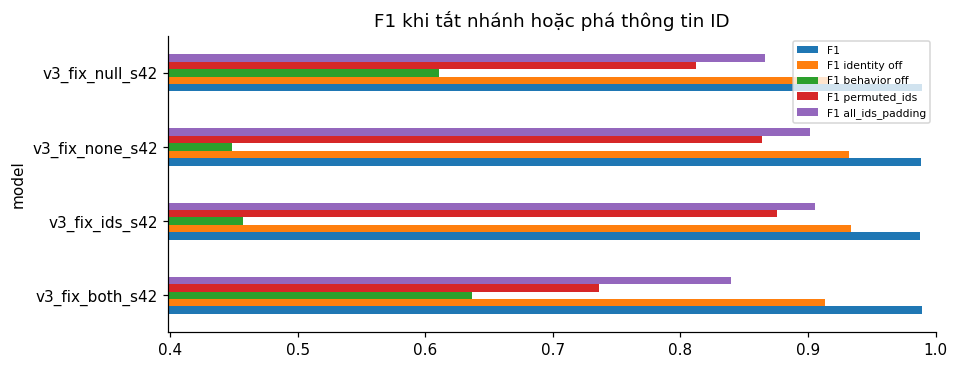

,model,task,xb,identity,behavior_raw,behavior,chance
0,v3_fix_both_s42,can_id_top20 (benign nodes),0.626,1.000,0.458,0.497,0.050
1,v3_fix_both_s42,attacked_or_not,0.921,0.945,0.939,0.941,0.500
2,v3_fix_both_s42,attack_class (attacked nodes),0.784,0.829,0.916,0.930,0.111
3,v3_fix_ids_s42,can_id_top20 (benign nodes),0.623,1.000,0.456,0.651,0.050
4,v3_fix_ids_s42,attacked_or_not,0.920,0.948,0.941,0.944,0.500
5,v3_fix_ids_s42,attack_class (attacked nodes),0.786,0.831,0.922,0.936,0.111
6,v3_fix_none_s42,can_id_top20 (benign nodes),0.622,1.000,0.453,0.648,0.050
7,v3_fix_none_s42,attacked_or_not,0.921,0.933,0.940,0.944,0.500
8,v3_fix_none_s42,attack_class (attacked nodes),0.783,0.826,0.918,0.932,0.111
9,v3_fix_null_s42,can_id_top20 (benign nodes),0.630,1.000,0.456,0.494,0.050


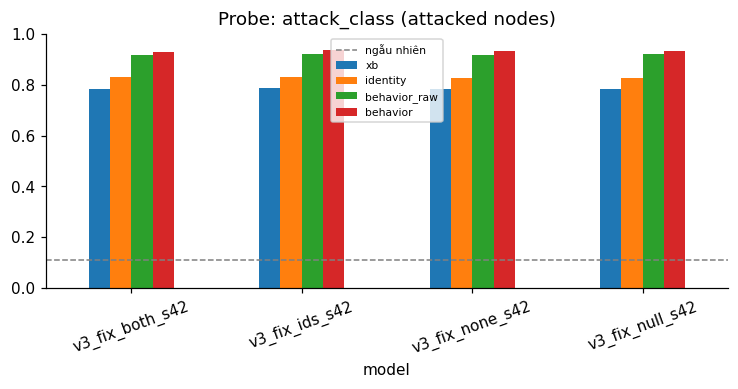

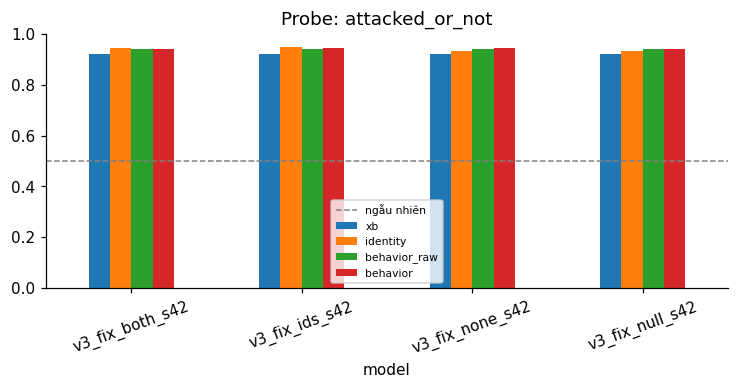

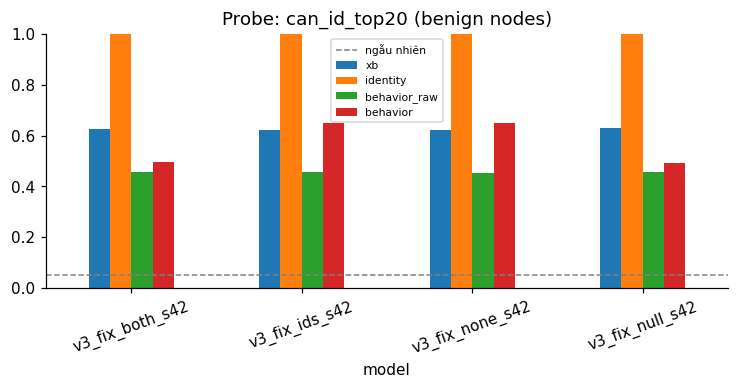

In [3]:
rows, probe_rows = [], []
for f in sorted(glob.glob(str(SAVE / "v3/diag/*.json"))):
    d = json.load(open(f)); name = Path(f).stem
    r = {"model": name, "F1": d["baseline"]["macro_f1"], "FPR": d["baseline"]["normal_fpr"]}
    if "A_null" in d:
        r["null ratio (benign/attacked)"] = d["A_null"]["ratio_benign_over_attacked"]
        r["real weight benign"] = d["A_null"]["real_weight_benign"]
    for br, m in d.get("B_branch_off", {}).items():
        r[f"F1 {br} off"] = m["macro_f1"]
    for k, m in d.get("C_id_reliance", {}).items():
        r[f"F1 {k}"] = m["macro_f1"]
    rows.append(r)
    for task, res in d.get("D_probes", {}).items():
        probe_rows.append({"model": name, "task": task, **res})
diag = pd.DataFrame(rows)
if len(diag):
    display(diag.round(4))
    cols = [c for c in diag.columns if c.startswith("F1 ")]
    ax = diag.set_index("model")[["F1"] + cols].plot.barh(figsize=(9, 0.5 * len(diag) + 1.5))
    ax.set_xlim(max(0, diag[["F1"] + cols].min().min() - 0.05), 1.0)
    ax.set_title("F1 khi tắt nhánh hoặc phá thông tin ID"); ax.legend(fontsize=7)
    savefig("fig0b_branch_diagnostics"); plt.show()
if probe_rows:
    pr = pd.DataFrame(probe_rows)
    display(pr.round(3))
    for task, g in pr.groupby("task"):
        reps = [c for c in ("xb", "identity", "behavior_raw", "behavior") if c in g]
        ax = g.set_index("model")[reps].plot.bar(figsize=(8, 3), rot=20)
        ax.axhline(g["chance"].iloc[0], ls="--", color="gray", lw=1, label="ngẫu nhiên")
        ax.set_title(f"Probe: {task}"); ax.set_ylim(0, 1); ax.legend(fontsize=7)
        savefig(f"fig0b_probe_{task.split()[0]}"); plt.show()

## 1. Quỹ đạo CL của mô hình cuối (C3: quyết định ignore / reuse / expand)

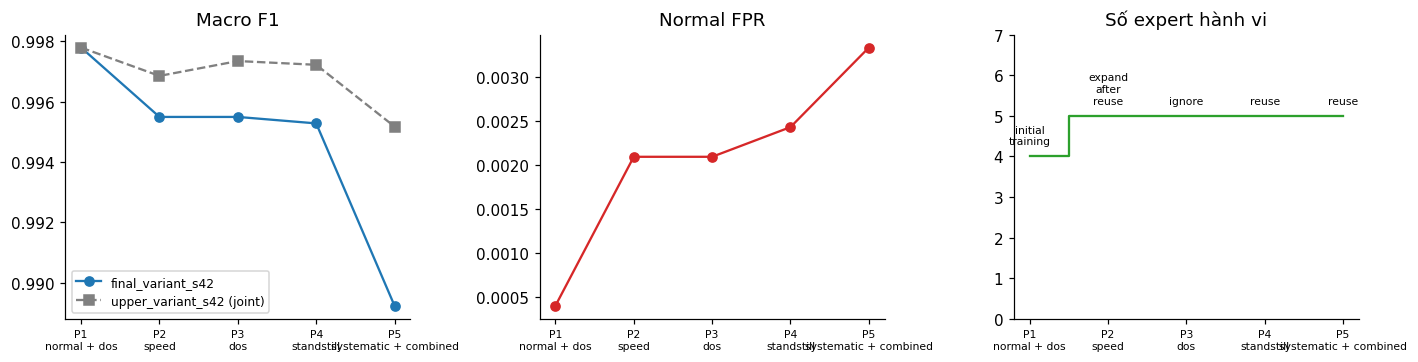

,phase,decision,experts,macro_f1,normal_fpr,detection
0,phase1,initial_training,4,0.997792,0.000400,0.995941
1,phase2,expand_after_reuse,5,0.995492,0.002093,0.994961
2,phase3,ignore,5,0.995492,0.002093,0.994961
3,phase4,reuse,5,0.995277,0.002430,0.995555
4,phase5,reuse,5,0.989228,0.003333,0.984664


In [4]:
def trajectory(run, ref=None, name="fig1_trajectory"):
    ph = [r["phase"] for r in run["results"]]
    x = np.arange(len(ph))
    f1 = [r["overall"]["macro_f1"] for r in run["results"]]
    fpr = [r["overall"]["normal_fpr"] for r in run["results"]]
    nexp = [r.get("num_experts", np.nan) for r in run["results"]]
    dec = [r.get("decision_info", {}).get("decision", "") for r in run["results"]]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    axes[0].plot(x, f1, "o-", label=run["name"])
    if ref:
        axes[0].plot(x[:len(ref["results"])], [r["overall"]["macro_f1"] for r in ref["results"]],
                     "s--", color="gray", label=f"{ref['name']} (joint)")
    axes[0].set_title("Macro F1"); axes[0].legend(fontsize=8)
    axes[1].plot(x, fpr, "o-", color="tab:red"); axes[1].set_title("Normal FPR")
    axes[2].step(x, nexp, where="mid", color="tab:green"); axes[2].set_title("Số expert hành vi")
    axes[2].set_ylim(0, max(nexp) + 2)
    for ax in axes:
        ax.set_xticks(x); ax.set_xticklabels([plabel(run, p) for p in ph], fontsize=7)
    for i, d in enumerate(dec):
        axes[2].annotate(d.replace("_", "\n"), (x[i], nexp[i]), textcoords="offset points",
                         xytext=(0, 8), ha="center", fontsize=7)
    fig.tight_layout(); savefig(name); plt.show()

if final:
    trajectory(final, upper)
    display(pd.DataFrame([{"phase": r["phase"], "decision": r.get("decision_info", {}).get("decision"),
                           "experts": r.get("num_experts"), "macro_f1": r["overall"]["macro_f1"],
                           "normal_fpr": r["overall"]["normal_fpr"],
                           "detection": r["overall"]["detection_rate"]} for r in final["results"]]))

## 2. F1 từng lớp qua các phase và ma trận nhầm lẫn (C2: không quên; C4: ít báo động giả)

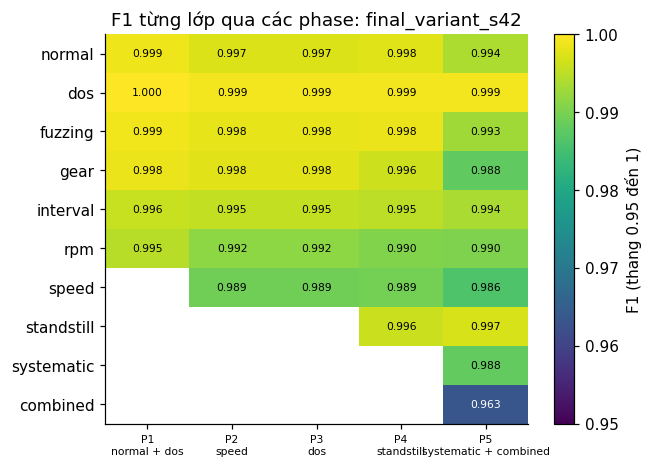

,normal,dos,fuzzing,gear,interval,rpm,speed,standstill
forgetting,0.0048,0.0009,0.006,0.0107,0.0023,0.0043,0.0032,-0.001


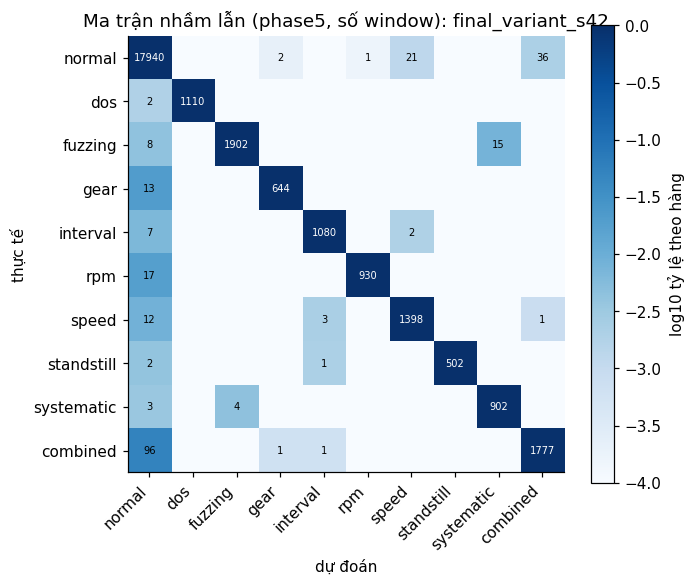

In [5]:
def per_class_heatmap(run, name="fig2_per_class_f1"):
    ph = [r["phase"] for r in run["results"]]
    M = np.full((len(CLASS_NAMES), len(ph)), np.nan)
    for j, r in enumerate(run["results"]):
        for i, c in enumerate(CLASS_NAMES):
            v = r["per_attack"].get(c)
            if v is not None and v > 0:
                M[i, j] = v
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    im = ax.imshow(M, vmin=0.95, vmax=1.0, cmap="viridis", aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if not np.isnan(M[i, j]):
                ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] < 0.975 else "black")
    ax.set_xticks(range(len(ph))); ax.set_xticklabels([plabel(run, p) for p in ph], fontsize=7)
    ax.set_yticks(range(len(CLASS_NAMES))); ax.set_yticklabels(CLASS_NAMES)
    plt.colorbar(im, ax=ax, label="F1 (thang 0.95 đến 1)")
    ax.set_title(f"F1 từng lớp qua các phase: {run['name']}")
    savefig(name); plt.show()
    # forgetting: best F1 earlier minus final F1
    fg = {c: np.nanmax(M[i, :-1]) - M[i, -1] for i, c in enumerate(CLASS_NAMES)
          if np.isfinite(M[i, :-1]).any() and np.isfinite(M[i, -1])}
    return pd.Series(fg, name="forgetting").round(4)

def confusion(run, phase="phase5", name="fig2_confusion"):
    p = load_preds(run["dir"], phase)
    if p is None:
        return
    y, yh = p["y"], p["logits"].astype(np.float32).argmax(1)
    K = len(CLASS_NAMES)
    cm = np.zeros((K, K)); np.add.at(cm, (y, yh), 1)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    im = ax.imshow(np.log10(cmn + 1e-4), cmap="Blues", vmin=-4, vmax=0)
    for i in range(K):
        for j in range(K):
            if cm[i, j] > 0 and (i != j or True):
                ax.text(j, i, f"{int(cm[i, j])}", ha="center", va="center", fontsize=6.5,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("dự đoán"); ax.set_ylabel("thực tế")
    cb = plt.colorbar(im, ax=ax); cb.set_label("log10 tỷ lệ theo hàng")
    ax.set_title(f"Ma trận nhầm lẫn ({phase}, số window): {run['name']}")
    savefig(name); plt.show()

if final:
    display(per_class_heatmap(final).to_frame().T)
    confusion(final)

## 3. Route heatmap (C1: expert chuyên môn hóa theo hành vi tấn công, không theo CAN ID)

- **3a.** Khối lượng routing trung bình của các node bị tấn công, theo lớp × expert, ở từng phase (cột đầu là null expert). Hàng `normal (benign)` dùng các node không bị tấn công.
- **3b.** Ở phase 5, mỗi hàng là một cặp (CAN ID, lớp). **Cùng một CAN ID nhưng khác attack** (ví dụ 0x0C9 cho rpm và standstill) mà đi vào expert khác nhau là bằng chứng routing theo hành vi; **khác ID nhưng cùng attack** (fuzzing, systematic trên hàng trăm ID) mà dùng chung một expert cũng vậy.

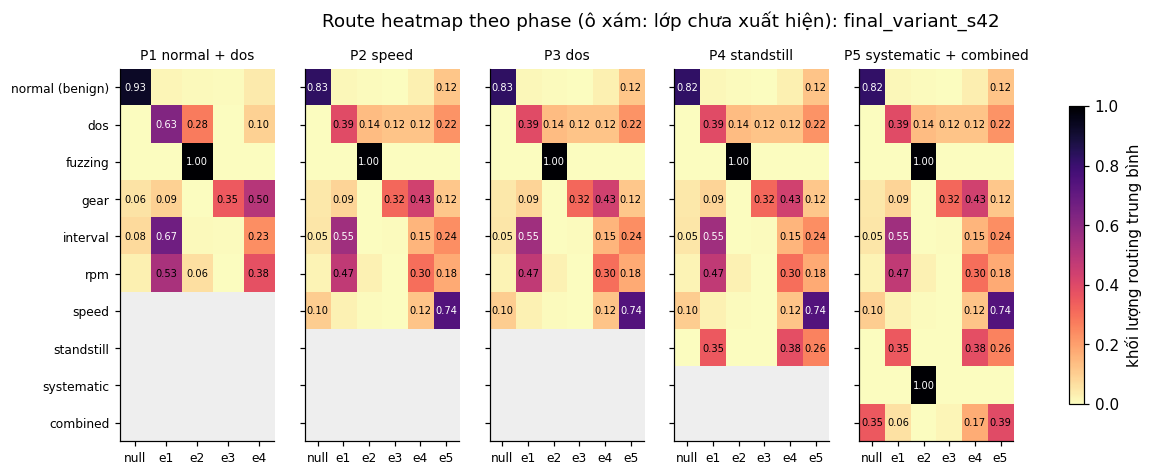

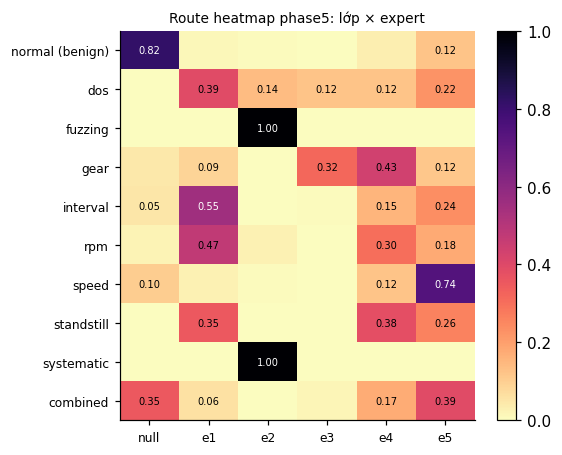

In [6]:
def node_mass(nodes, sel):
    pr = nodes["node_probs"][sel].astype(np.float32)
    return pr.mean(0) if len(pr) else None

ROW_LABELS = ["normal (benign)"] + ATTACKS

def routing_matrix(run, phase, min_nodes=20):
    """Rows: benign nodes + every attack class (NaN until the class has attacked nodes)."""
    p = load_preds(run["dir"], phase)
    if p is None or "node_probs" not in p:
        return None
    atk = p["node_atk"] > 0
    ny = p["node_ny"]
    M = np.full((len(ROW_LABELS), p["node_probs"].shape[1]), np.nan)
    m = node_mass(p, ~atk)
    if m is not None:
        M[0] = m
    for c in range(1, len(CLASS_NAMES)):
        sel = atk & (ny == c)
        if sel.sum() >= min_nodes:
            M[c] = node_mass(p, sel)
    return M

def draw_routing(ax, M, labels, title, show_labels=True):
    cmap = plt.get_cmap("magma_r").copy(); cmap.set_bad("#eeeeee")
    im = ax.imshow(np.ma.masked_invalid(M), vmin=0, vmax=1, cmap=cmap, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]) and M[i, j] >= 0.05:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                        color="white" if M[i, j] > 0.55 else "black")
    ax.set_xticks(range(M.shape[1]))
    ax.set_xticklabels(["null"] + [f"e{k}" for k in range(1, M.shape[1])], fontsize=8)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels if show_labels else [], fontsize=8)
    ax.set_title(title, fontsize=9)
    return im

if final:
    mats = [(ph, routing_matrix(final, ph)) for ph in PHASES]
    mats = [t for t in mats if t[1] is not None]
    fig, axes = plt.subplots(1, len(mats), figsize=(2.3 * len(mats) + 1.6, 4.4), squeeze=False)
    for k, (ax, (ph, M)) in enumerate(zip(axes[0], mats)):
        im = draw_routing(ax, M, ROW_LABELS, plabel(final, ph).replace("\n", " "), show_labels=(k == 0))
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label="khối lượng routing trung bình")
    fig.suptitle(f"Route heatmap theo phase (ô xám: lớp chưa xuất hiện): {final['name']}", y=1.0)
    savefig("fig3a_route_heatmap_phases"); plt.show()

    ph, M = mats[-1]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    im = draw_routing(ax, M, ROW_LABELS, f"Route heatmap {ph}: lớp × expert")
    plt.colorbar(im, ax=ax)
    savefig("fig3a_route_heatmap_final"); plt.show()

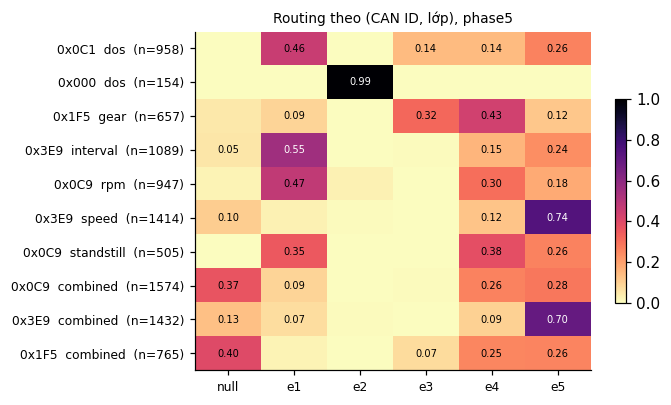

CAN ID dùng chung cho nhiều attack (routing theo hành vi nếu top_expert khác nhau):


,can_id,class,n,top_expert,top_mass
0,0x000,dos,154,e2,0.994
1,0x0C1,dos,958,e1,0.456
4,0x0C9,combined,1574,null,0.367
2,0x0C9,rpm,947,e1,0.473
3,0x0C9,standstill,505,e4,0.382
5,0x0F1,combined,172,null,0.693
6,0x1F1,combined,244,null,0.868
8,0x1F5,combined,765,null,0.397
7,0x1F5,gear,657,e4,0.434
9,0x2F9,combined,177,null,0.665


In [7]:
def id_lookup(data_dir):
    meta = Path(data_dir) / "metadata.json"
    if not meta.exists():
        return lambda i: f"#{i}"
    vocab = json.load(open(meta))["vocab"]
    inv = {int(v): int(k) for k, v in vocab.items()}
    return lambda i: f"0x{inv[i]:03X}" if i in inv else f"#{i}"

def id_class_heatmap(run, data_dir, phase="phase5", min_nodes=30, max_rows=28,
                     name="fig3b_route_by_canid"):
    p = load_preds(run["dir"], phase)
    if p is None or "node_probs" not in p:
        return
    to_hex = id_lookup(data_dir)
    atk = p["node_atk"] > 0
    ids, ny, pr = p["node_ids"][atk], p["node_ny"][atk], p["node_probs"][atk].astype(np.float32)
    df = pd.DataFrame({"id": ids, "cls": ny})
    counts = df.groupby(["cls", "id"]).size().reset_index(name="n")
    counts = counts[counts.n >= min_nodes]
    # keep the IDs carrying most attacked nodes for each class, at most max_rows rows
    counts = counts.sort_values(["cls", "n"], ascending=[True, False]).groupby("cls").head(3)
    counts = counts.head(max_rows)
    rows, labels = [], []
    for _, r in counts.iterrows():
        sel = (ids == r.id) & (ny == r.cls)
        rows.append(pr[sel].mean(0))
        labels.append(f"{to_hex(int(r.id))}  {CLASS_NAMES[int(r.cls)]}  (n={int(r.n)})")
    if not rows:
        return
    M = np.vstack(rows)
    fig, ax = plt.subplots(figsize=(5.8, 0.28 * len(rows) + 1.2))
    im = draw_routing(ax, M, labels, f"Routing theo (CAN ID, lớp), {phase}")
    plt.colorbar(im, ax=ax, shrink=0.6)
    savefig(name); plt.show()
    # same ID, different classes: does routing change?
    shared = df.groupby("id")["cls"].nunique()
    shared = shared[shared > 1].index
    out = []
    for i in shared:
        for c in np.unique(ny[ids == i]):
            sel = (ids == i) & (ny == c)
            if sel.sum() >= min_nodes:
                m = pr[sel].mean(0)
                names = ["null"] + [f"e{k}" for k in range(1, len(m))]
                out.append({"can_id": to_hex(int(i)), "class": CLASS_NAMES[int(c)], "n": int(sel.sum()),
                            "top_expert": names[int(m.argmax())], "top_mass": round(float(m.max()), 3)})
    if out:
        print("CAN ID dùng chung cho nhiều attack (routing theo hành vi nếu top_expert khác nhau):")
        display(pd.DataFrame(out).sort_values(["can_id", "class"]).head(30))

if final:
    id_class_heatmap(final, FINAL_DATA)

## 4. Chuyên môn hóa và độ ổn định routing (C1, C2)

,phase,experts,null_benign,null_attacked,"NMI(expert, class)","NMI(expert, CAN ID)"
0,phase1,4,0.968,0.008,0.695,0.153
1,phase2,5,0.921,0.011,0.669,0.195
2,phase3,5,0.921,0.011,0.669,0.195
3,phase4,5,0.920,0.011,0.641,0.201
4,phase5,5,0.916,0.069,0.530,0.194


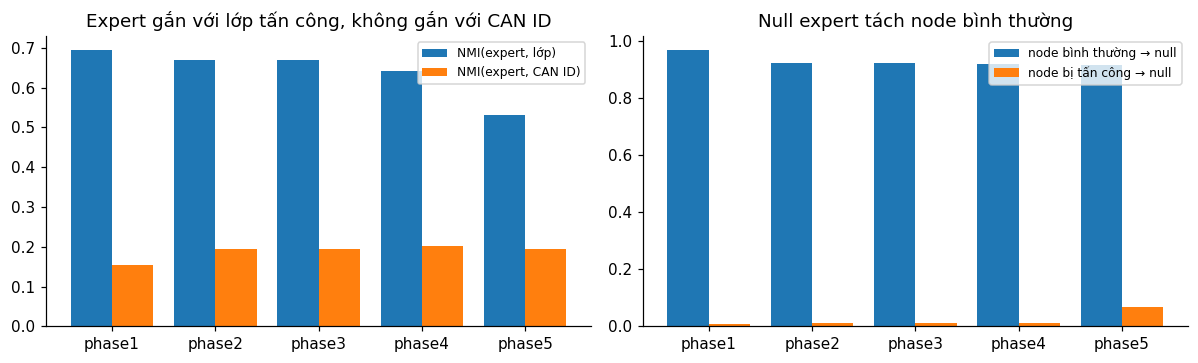

phase,phase1,phase2,phase3,phase4,phase5
class,,,,,
combined,NaN,NaN,NaN,NaN,0.000
dos,0.0,0.372,0.372,0.372,0.372
fuzzing,0.0,0.002,0.002,0.002,0.002
gear,0.0,0.115,0.115,0.115,0.115
interval,0.0,0.235,0.235,0.235,0.235
rpm,0.0,0.178,0.178,0.178,0.178
speed,NaN,0.000,0.000,0.000,0.000
standstill,NaN,NaN,NaN,0.000,0.000
systematic,NaN,NaN,NaN,NaN,0.000


In [8]:
def specialization_table(run):
    rows = []
    for r in run["results"]:
        s = r.get("specialization") or {}
        rows.append({"phase": r["phase"], "experts": r.get("num_experts"),
                     "null_benign": s.get("null_rate_benign_nodes"),
                     "null_attacked": s.get("null_rate_attacked_nodes"),
                     "NMI(expert, class)": s.get("nmi_active_class"),
                     "NMI(expert, CAN ID)": s.get("nmi_active_canid")})
    return pd.DataFrame(rows)

def stability(run):
    """Total-variation distance of each class's routing mass from the phase where it was learned."""
    first, rows = {}, []
    for r in run["results"]:
        em = (r.get("specialization") or {}).get("expert_mass", {})
        for c, m in em.items():
            m = np.array(m, dtype=float)
            if c not in first:
                first[c] = m
            ref = np.zeros(max(len(m), len(first[c]))); ref[:len(first[c])] = first[c]
            cur = np.zeros_like(ref); cur[:len(m)] = m
            rows.append({"phase": r["phase"], "class": c, "tv": 0.5 * np.abs(cur - ref).sum()})
    return pd.DataFrame(rows).pivot(index="class", columns="phase", values="tv")

if final:
    st = specialization_table(final)
    display(st.round(3))
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    x = np.arange(len(st))
    axes[0].bar(x - 0.2, st["NMI(expert, class)"], 0.4, label="NMI(expert, lớp)")
    axes[0].bar(x + 0.2, st["NMI(expert, CAN ID)"], 0.4, label="NMI(expert, CAN ID)")
    axes[0].set_xticks(x); axes[0].set_xticklabels(st["phase"]); axes[0].legend(fontsize=8)
    axes[0].set_title("Expert gắn với lớp tấn công, không gắn với CAN ID")
    axes[1].bar(x - 0.2, st["null_benign"], 0.4, label="node bình thường → null")
    axes[1].bar(x + 0.2, st["null_attacked"], 0.4, label="node bị tấn công → null")
    axes[1].set_xticks(x); axes[1].set_xticklabels(st["phase"]); axes[1].legend(fontsize=8)
    axes[1].set_title("Null expert tách node bình thường")
    fig.tight_layout(); savefig("fig4_specialization"); plt.show()
    tv = stability(final)
    display(tv.round(3))

### 4b. Độ ổn định routing: đóng băng expert (bb) so với mở toàn bộ

Trung bình khoảng cách total variation của 5 lớp ban đầu giữa phase 1 và phase 5, trên các run quét bộ nhớ (cùng dữ liệu z-score).

In [ ]:
def drift(run, classes=("dos", "fuzzing", "gear", "interval", "rpm")):
    em1 = (run["by_phase"].get("phase1", {}).get("specialization") or {}).get("expert_mass", {})
    em5 = (run["by_phase"].get("phase5", {}).get("specialization") or {}).get("expert_mass", {})
    d = []
    for c in classes:
        if c in em1 and c in em5:
            a, b = np.array(em1[c]), np.array(em5[c])
            ref = np.zeros(len(b)); ref[:len(a)] = a
            d.append(0.5 * np.abs(b - ref).sum())
    return np.mean(d) if d else np.nan

rows = []
for mode in ("bb", "open"):
    for r in runs_matching(f"seeds_memory/impala/{mode}_res_*_s*"):
        if "nonew" in r["name"]:
            continue
        rows.append({"mode": mode, "run": r["name"], "drift": drift(r)})
dr = pd.DataFrame(rows)
if len(dr):
    display(dr.groupby("mode")["drift"].agg(["mean", "std", "count"]).round(3))
    fig, ax = plt.subplots(figsize=(3.6, 3))
    for i, mode in enumerate(("bb", "open")):
        v = dr[dr["mode"] == mode]["drift"]
        ax.scatter(np.full(len(v), i) + np.random.uniform(-0.08, 0.08, len(v)), v, alpha=0.6)
        ax.errorbar(i, v.mean(), v.std(), fmt="o", color="black", capsize=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["đóng băng\nexpert (bb)", "mở toàn bộ"])
    ax.set_ylabel("routing drift P1→P5 (TV)")
    savefig("fig4b_routing_drift"); plt.show()

## 5. So sánh với MoE chuẩn, ablation, chính sách replay và cận trên (C1, C4)

In [ ]:
GROUPS = [  # (nhóm, tên, mẫu thư mục)
    ("final",     "Cuối: surprise + payload, label + routing", "v3/impala/final_variant_s*"),
    ("final",     "Cuối, luôn tái sử dụng",          "v3/impala/reuse_only_variant_s*"),
    ("reference", "Cận trên joint (dữ liệu cuối)",  "v3/impala/upper_variant_s*"),
    ("variant",   "Surprise",                        "surprise/impala/bb_res_10k_surprise_s*"),
    ("variant",   "Payload",                         "payload/impala/bb_res_10k_pay_s*"),
    ("variant",   "z-score (cấu hình cuối cũ)",      "seeds_memory/impala/bb_res_10k_s*"),
    ("reference", "Cận trên joint (z-score)",        "memory/impala/upper_full_retrain"),
    ("baseline",  "MoE chuẩn, đóng băng expert",     "ablation_final/impala/std_moe_s*"),
    ("baseline",  "MoE chuẩn, mở toàn bộ",           "ablation_final/impala/std_moe_open_s*"),
    ("ablation",  "Bỏ đặc trưng window",             "ablation_final/impala/no_window_s*"),
    ("ablation",  "Bỏ active loss",                  "ablation_final/impala/no_active_s*"),
    ("ablation",  "Bỏ identity dropout",             "ablation_final/impala/no_iddrop_s*"),
    ("ablation",  "Bỏ logit adjustment",             "ablation_final/impala/no_la_s*"),
    ("ablation",  "Bỏ distillation",                 "ablation_final/impala/no_distill_s*"),
    ("ablation",  "Quyết định ba nhánh (dual)",      "ablation_final/impala/dual_s*"),
    ("replay",    "Class-balanced (CBRS)",           ["ablation_final/impala/classbal_s*", "memory/impala/mem_classbal_10k"]),
    ("replay",    "Benign-anchored",                 ["ablation_final/impala/anchor_s*", "memory/impala/mem_anchor_10k"]),
    ("replay",    "Bỏ normal của bản ghi mới",       "seeds_memory/impala/bb_res_10k_nonew_s*"),
]
rows = []
for grp, label, pat in GROUPS:
    runs = runs_matching(pat)
    if not runs:
        continue
    f1 = stat(runs, lambda r: last(r)["overall"]["macro_f1"])
    fpr = stat(runs, lambda r: last(r)["overall"]["normal_fpr"])
    fg = stat(runs, lambda r: r["cl"].get("forgetting_mean", np.nan))
    nt = {len(load_preds(r["dir"])["y"]) for r in runs if load_preds(r["dir"]) is not None}
    rows.append({"group": grp, "config": label, "n_seeds": f1[2], "f1": f1[0], "f1_std": f1[1],
                 "fpr": fpr[0], "fpr_std": fpr[1], "forgetting_mean": fg[0],
                 "experts": stat(runs, lambda r: last(r).get("num_experts", np.nan))[0],
                 "n_test": "/".join(map(str, sorted(nt)))})
comp = pd.DataFrame(rows)
display(comp.round(4))

COLORS = {"final": "tab:red", "variant": "tab:orange", "baseline": "tab:gray",
          "ablation": "tab:blue", "replay": "tab:purple", "reference": "black"}
if len(comp):
    c = comp.iloc[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.38 * len(c) + 1.4), sharey=True)
    y = np.arange(len(c))
    axes[0].barh(y, c["f1"], xerr=c["f1_std"].fillna(0), color=[COLORS[g] for g in c["group"]])
    axes[0].set_xlim(max(0.94, c["f1"].min() - 0.01), 1.0); axes[0].set_title("Macro F1 (phase 5)")
    axes[1].barh(y, c["fpr"], xerr=c["fpr_std"].fillna(0), color=[COLORS[g] for g in c["group"]])
    axes[1].set_xscale("log"); axes[1].set_title("Normal FPR (log)")
    axes[0].set_yticks(y); axes[0].set_yticklabels([f"{l}  [n={n}]" for l, n in zip(c["config"], c["n_seeds"])])
    from matplotlib.patches import Patch
    axes[1].legend(handles=[Patch(color=col, label=g) for g, col in COLORS.items()
                            if g in set(c["group"])], fontsize=8, loc="lower right")
    fig.tight_layout(); savefig("fig5_comparison"); plt.show()
    print("Lưu ý: chỉ so sánh trực tiếp các dòng có cùng n_test (cột cuối bảng).")

## 6. Bộ nhớ replay: F1 và forgetting theo M (C2, C4)

In [ ]:
rows = []
for mode in ("bb", "open"):
    for M in ("1k", "2k", "5k", "10k"):
        runs = runs_matching(f"seeds_memory/impala/{mode}_res_{M}_s*")
        if runs:
            f1 = stat(runs, lambda r: last(r)["overall"]["macro_f1"])
            fg = stat(runs, lambda r: r["cl"].get("forgetting_mean", np.nan))
            fpr = stat(runs, lambda r: last(r)["overall"]["normal_fpr"])
            rows.append({"mode": mode, "M": int(M[:-1]) * 1000, "f1": f1[0], "f1_std": f1[1],
                         "forgetting": fg[0], "forgetting_std": fg[1], "fpr": fpr[0], "n": f1[2]})
mem = pd.DataFrame(rows)
if len(mem):
    display(mem.round(4))
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
    for mode, lab in (("bb", "đóng băng expert (bb)"), ("open", "mở toàn bộ")):
        d = mem[mem["mode"] == mode].sort_values("M")
        axes[0].errorbar(d["M"], d["f1"], d["f1_std"], marker="o", capsize=3, label=lab)
        axes[1].errorbar(d["M"], d["forgetting"], d["forgetting_std"], marker="o", capsize=3, label=lab)
        axes[2].plot(d["M"], d["fpr"], marker="o", label=lab)
    refs = {"M = 20k (1 seed)": "memory/impala/mem_prior_strat_20k",
            "replay không giới hạn": "memory/impala/unbounded_ratio_bb",
            "cận trên joint": "memory/impala/upper_full_retrain"}
    for (lab, pat), ls in zip(refs.items(), (":", "-.", "--")):
        r = runs_matching(pat)
        if r:
            axes[0].axhline(last(r[0])["overall"]["macro_f1"], ls=ls, color="gray", lw=1, label=lab)
    for ax, t in zip(axes, ("Macro F1", "Forgetting trung bình", "Normal FPR")):
        ax.set_xscale("log"); ax.set_xlabel("kích thước bộ nhớ M (window)"); ax.set_title(t)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); savefig("fig6_memory"); plt.show()

## 7. Cross-vehicle: chuyển giao không huấn luyện lại (hỗ trợ C1)

In [ ]:
rows = []
for f in sorted(glob.glob(str(SAVE / "cross_vehicle/*/cross_eval.json"))):
    setting = Path(f).parent.name
    for r in json.load(open(f)):
        row = {"setting": setting, "run": r["run"], "arch": r.get("arch"),
               "macro_f1": r["macro_f1"], "bin_gmean": r["bin_gmean"], "bin_f1": r["bin_f1"],
               "normal_fpr": r["normal_fpr"], "tpr": r["bin_tpr"]}
        row.update({a: r.get(f"f1_{a}") for a in ATTACKS})
        rows.append(row)
cross = pd.DataFrame(rows)
if len(cross):
    cross["model"] = cross["setting"].str.replace("impala_to_", "") + " | " + cross["run"]
    display(cross[["model", "macro_f1", "bin_gmean", "normal_fpr", "tpr"]].round(3))
    fig, axes = plt.subplots(1, 3, figsize=(13, 0.35 * len(cross) + 1.6), sharey=True)
    y = np.arange(len(cross))
    col = ["tab:gray" if a == "cosine" else "tab:red" for a in cross["arch"]]
    for ax, k, t in zip(axes, ("macro_f1", "bin_gmean", "normal_fpr"),
                        ("F1 10 lớp", "g-mean nhị phân", "Normal FPR (log)")):
        ax.barh(y, cross[k], color=col); ax.set_title(t)
    axes[2].set_xscale("log")
    axes[0].set_yticks(y); axes[0].set_yticklabels(cross["model"], fontsize=8)
    fig.suptitle("Xám: MoE chuẩn (theo CAN ID); đỏ: MoE hành vi", fontsize=9)
    fig.tight_layout(); savefig("fig7_cross_vehicle"); plt.show()

    H = cross[ATTACKS].astype(float).values
    fig, ax = plt.subplots(figsize=(8.5, 0.35 * len(cross) + 1.4))
    im = ax.imshow(H, vmin=0, vmax=1, cmap="RdYlGn", aspect="auto")
    for i in range(H.shape[0]):
        for j in range(H.shape[1]):
            ax.text(j, i, f"{H[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(ATTACKS))); ax.set_xticklabels(ATTACKS, rotation=30, ha="right")
    ax.set_yticks(range(len(cross))); ax.set_yticklabels(cross["model"], fontsize=8)
    plt.colorbar(im, ax=ax, label="F1 trên xe đích")
    ax.set_title("Attack nào chuyển giao được")
    savefig("fig7b_cross_vehicle_per_attack"); plt.show()

## 7b. Thứ tự phase: khi nào cần mở rộng (C3)

So sánh quy tắc đề xuất (`final_*`: label + kiểm tra routing, mở rộng khi expert hiện có không phục vụ hành vi mới) với `reuse_only_*` (luôn tái sử dụng) trên ba thứ tự phase. Ở `late_injection` và `late_spoof`, một kiểu hành vi vắng mặt ở phase 1, nên mở rộng được kỳ vọng là cần thiết.

In [ ]:
ORDERS = {"variant": None, "late_injection": "fuzzing", "late_spoof": "gear"}  # lớp mang hành vi mới
rows = []
for order, novel in ORDERS.items():
    for mode, label in (("final", "label + routing"), ("reuse_only", "luôn tái sử dụng")):
        r = load_run(SAVE / f"v3/impala/{mode}_{order}_s42")
        if not r:
            continue
        lr = last(r); sp = lr.get("specialization") or {}
        rows.append({"order": order, "rule": label, "f1": lr["overall"]["macro_f1"],
                     "fpr": lr["overall"]["normal_fpr"], "experts": lr.get("num_experts"),
                     "decisions": " / ".join(x.get("decision_info", {}).get("decision", "")[:10]
                                             for x in r["results"][1:]),
                     "NMI(expert, class)": sp.get("nmi_active_class"),
                     "null_attacked": sp.get("null_rate_attacked_nodes"),
                     f"F1 lớp hành vi mới": lr["per_attack"].get(novel) if novel else None,
                     "forgetting_mean": r["cl"].get("forgetting_mean")})
orders = pd.DataFrame(rows)
if len(orders):
    display(orders.round(4))
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
    for ax, k, t in zip(axes, ("f1", "experts", "NMI(expert, class)", "null_attacked"),
                        ("Macro F1", "Số expert", "NMI(expert, lớp) phase cuối", "Node tấn công → null")):
        piv = orders.pivot(index="order", columns="rule", values=k)
        piv.plot.bar(ax=ax, rot=0, legend=(k == "f1")); ax.set_title(t); ax.set_xlabel("")
    fig.tight_layout(); savefig("fig7c_phase_orders"); plt.show()

## 8. Xuất bảng (CSV và LaTeX)

In [ ]:
def to_latex(df, path, cols, fmt="{:.4f}"):
    lines = ["\\begin{tabular}{l" + "r" * (len(cols) - 1) + "}", "\\toprule",
             " & ".join(cols) + " \\\\", "\\midrule"]
    for _, r in df[cols].iterrows():
        lines.append(" & ".join(fmt.format(v) if isinstance(v, float) else str(v) for v in r) + " \\\\")
    lines += ["\\bottomrule", "\\end{tabular}"]
    Path(path).write_text("\n".join(lines))

if "comp" in globals() and len(comp):
    comp.to_csv(FIG / "table_comparison.csv", index=False)
    to_latex(comp, FIG / "table_comparison.tex", ["config", "n_seeds", "f1", "f1_std", "fpr", "forgetting_mean"])
if "mem" in globals() and len(mem):
    mem.to_csv(FIG / "table_memory.csv", index=False)
if "cross" in globals() and len(cross):
    cross.to_csv(FIG / "table_cross_vehicle.csv", index=False)
if final:
    specialization_table(final).to_csv(FIG / "table_specialization.csv", index=False)
if "orders" in globals() and len(orders):
    orders.to_csv(FIG / "table_phase_orders.csv", index=False)
print("Đã lưu vào", FIG.resolve())